# WattIf : préparation des données
Consommation électrique France (RTE éCO2mix) + température (ODRÉ), 2016-2026

In [ ]:
# Cellule de tête : vérifie la présence des données brutes, trop volumineuses pour être fournies avec le projet.
# Pourquoi : sans elles, la suite de ce notebook ne peut pas s'exécuter ; on l'annonce clairement au lieu d'échouer plus loin,
# et on montre que le fichier préparé data/daily.csv (fourni) suffit aux autres notebooks.
import os
import pandas as pd

SOURCES = {
    "data/raw/eco2mix-national-cons-def.csv":
        "https://odre.opendatasoft.com/api/explore/v2.1/catalog/datasets/eco2mix-national-cons-def/exports/csv?delimiter=%3B&use_labels=true",
    "data/raw/temperature-quotidienne-regionale.csv":
        "https://odre.opendatasoft.com/api/explore/v2.1/catalog/datasets/temperature-quotidienne-regionale/exports/csv?delimiter=%3B&use_labels=true",
}
manquants = [chemin for chemin in SOURCES if not os.path.exists(chemin)]
if manquants:
    print("Données brutes absentes. Pour refaire la préparation, télécharger :")
    for chemin in manquants:
        print(f"  {chemin}\n    <- {SOURCES[chemin]}")
    print("Pages des jeux de données : https://odre.opendatasoft.com/explore/dataset/eco2mix-national-cons-def/")
    print("                            https://odre.opendatasoft.com/explore/dataset/temperature-quotidienne-regionale/")
    print("Attention : ces jeux sont mis à jour ; pour retrouver exactement data/daily.csv, ne garder que les dates jusqu'au 31/08/2026.")
    pret = pd.read_csv("data/daily.csv", index_col="date", parse_dates=True)
    print(f"\nBascule sur le fichier préparé data/daily.csv : {pret.shape[0]} jours, du {pret.index.min().date()} au {pret.index.max().date()}.")
    raise SystemExit("Préparation non réexécutée (data/raw/ absent) ; les autres notebooks utilisent data/daily.csv.")
print("Données brutes présentes : la préparation peut être réexécutée.")

In [1]:
# Imports et graine fixée : rend l'exécution reproductible ; `holidays` fournit le calendrier officiel des jours fériés français.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import holidays

np.random.seed(42)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.1.3


In [2]:
# On liste data/raw pour vérifier que les deux fichiers sources attendus sont présents avant de les lire.
os.listdir("data/raw")

['.ipynb_checkpoints',
 'eco2mix-national-cons-def.csv',
 'temperature-quotidienne-regionale.csv']

## 1. Chargement des données de consommation (RTE éCO2mix)
Fichier au pas de 15 minutes. On ne garde que les colonnes utiles au projet.

In [3]:
# On ne charge que les colonnes utiles : le fichier au pas de 15 minutes est volumineux et le reste ne sert pas au projet.
colonnes = ["Nature", "Date", "Heure", "Consommation (MW)", "Taux de CO2 (g/kWh)",
            "Nucléaire (MW)", "Gaz (MW)", "Eolien (MW)", "Solaire (MW)"]

elec = pd.read_csv("data/raw/eco2mix-national-cons-def.csv",
                   sep=";", usecols=colonnes, encoding="utf-8-sig")

print(elec.shape)
elec.head()

(374016, 9)


,Nature,Date,Heure,Consommation (MW),Gaz (MW),Nucléaire (MW),Eolien (MW),Solaire (MW),Taux de CO2 (g/kWh)
0,Données consolidées,2026-08-31,23:45,NaN,NaN,NaN,NaN,NaN,NaN
1,Données consolidées,2026-08-31,23:30,43979.0,3219.0,37002.0,3758.0,1.0,29.0
2,Données consolidées,2026-08-31,23:15,NaN,NaN,NaN,NaN,NaN,NaN
3,Données consolidées,2026-08-31,23:00,45070.0,3270.0,36863.0,3912.0,2.0,29.0
4,Données consolidées,2026-08-31,22:45,NaN,NaN,NaN,NaN,NaN,NaN


#### vérifier les valeurs manquantes :

In [4]:
# Comptage des valeurs manquantes : il décide si l'agrégation peut simplement les ignorer (moyenne) ou s'il faut les imputer.
elec.isna().sum()

Nature                      0
Date                        0
Heure                       0
Consommation (MW)      187009
Gaz (MW)               187009
Nucléaire (MW)         187009
Eolien (MW)            187009
Solaire (MW)           187009
Taux de CO2 (g/kWh)    187009
dtype: int64

## 2. Agrégation journalière
Les valeurs sont des puissances moyennes (MW). On prend la moyenne des MW sur la journée
(les NaN sont ignorés), puis × 24 h → MWh, ÷ 1000 → GWh.
La moyenne reste correcte quel que soit le pas (15 ou 30 min), contrairement à une somme.

#### contrôle avant d’agréger:
On vérifie combien de valeurs non vides on a par jour :

In [5]:
# Nombre de mesures non vides par jour : la moyenne journalière n'est comparable d'un jour à l'autre que si ce nombre est constant.
valeurs_par_jour = elec.groupby("Date")["Consommation (MW)"].count()
valeurs_par_jour.value_counts()

Consommation (MW)
48    3895
47       1
Name: count, dtype: int64

In [6]:
# On isole les jours incomplets pour juger si leur moyenne reste fiable.
valeurs_par_jour[valeurs_par_jour < 48]

Date
2026-01-01    47
Name: Consommation (MW), dtype: int64

#### l’agrégation :

In [7]:
# Moyenne des puissances (MW) × 24 h : indépendante du pas de mesure, contrairement à une somme ; elle donne des GWh/jour.
mw = ["Consommation (MW)", "Nucléaire (MW)", "Gaz (MW)", "Eolien (MW)", "Solaire (MW)"]

jour = elec.groupby("Date")[mw].mean() * 24 / 1000
jour.columns = ["conso_gwh", "nucleaire_gwh", "gaz_gwh", "eolien_gwh", "solaire_gwh"]

jour["taux_co2"] = elec.groupby("Date")["Taux de CO2 (g/kWh)"].mean()
jour["nature"] = elec.groupby("Date")["Nature"].first()

jour.index = pd.to_datetime(jour.index)
jour = jour.sort_index()

print(jour.shape, jour.index.min(), jour.index.max())
jour["conso_gwh"].describe()

(3896, 7) 2016-01-01 00:00:00 2026-08-31 00:00:00


count    3896.000000
mean     1254.038080
std       249.404389
min       854.849000
25%      1066.206500
50%      1170.358500
75%      1438.507875
max      2150.402000
Name: conso_gwh, dtype: float64

## 3. Température : moyenne nationale
Le fichier donne la température quotidienne pour les 13 régions métropolitaines.
On calcule une moyenne nationale simple (non pondérée par la population, limite à discuter).

#### charger et contrôler : 

In [8]:
# Contrôle de la température avant de moyenner : couverture des dates, nombre de régions et valeurs manquantes.
temp = pd.read_csv("data/raw/temperature-quotidienne-regionale.csv",
                   sep=";", encoding="utf-8-sig")

print(temp.shape, temp["Date"].min(), temp["Date"].max())
print("Régions :", temp["Région"].nunique())
print(temp.groupby("Date").size().value_counts())
temp.isna().sum()

(50557, 7) 2016-01-01 2026-09-30
Régions : 13
13    3889
Name: count, dtype: int64


ID                   0
Date                 0
Code INSEE région    0
Région               0
TMin (°C)            0
TMax (°C)            0
TMoy (°C)            0
dtype: int64

#### moyenne nationale par jour : 

In [9]:
# Moyenne simple des 13 régions : hypothèse simplificatrice (pas de pondération par la population), faute de poids dans la source.
temp_jour = temp.groupby("Date")[["TMoy (°C)", "TMin (°C)", "TMax (°C)"]].mean()
temp_jour.columns = ["temp_moy", "temp_min", "temp_max"]
temp_jour.index = pd.to_datetime(temp_jour.index)
temp_jour = temp_jour.sort_index()

print(temp_jour.shape)
temp_jour.describe()

(3889, 3)


,temp_moy,temp_min,temp_max
count,3889.000000,3889.000000,3889.000000
mean,13.549416,8.817780,18.281049
std,6.248296,5.467674,7.300039
min,-3.184615,-7.665385,0.153846
25%,8.577692,4.540769,12.417692
50%,13.053077,8.555385,17.787692
75%,18.853077,13.393846,24.094615
max,29.790000,21.903846,37.960769


## 4. Jours manquants dans les températures
37 jours sont absents du fichier ODRÉ (surtout des fins de mois), en trous isolés de 1 à 2 jours.
On les comble par interpolation linéaire dans le temps et on les signale (temp_interpolee = 1).
L'interpolation est faite avant de couper au 31/08/2026, pour que ce dernier jour ait une valeur d'appui.

#### repérer les trous :

In [10]:
# On repère les jours absents pour choisir un traitement adapté à leur forme (trous isolés d'un à deux jours).
calendrier = pd.date_range(temp_jour.index.min(), temp_jour.index.max(), freq="D")
temp_jour = temp_jour.reindex(calendrier)

manquants = temp_jour["temp_moy"].isna()
print("Jours manquants :", manquants.sum())
print(temp_jour.index[manquants].strftime("%Y-%m-%d").tolist())

Jours manquants : 37
['2021-04-30', '2022-07-31', '2022-08-31', '2023-01-31', '2023-02-28', '2023-08-31', '2023-10-31', '2024-03-31', '2024-04-30', '2024-05-31', '2024-06-30', '2024-07-31', '2024-08-31', '2024-09-30', '2024-10-31', '2024-11-30', '2024-12-30', '2024-12-31', '2025-01-31', '2025-02-28', '2025-03-31', '2025-04-30', '2025-05-31', '2025-06-30', '2025-07-31', '2025-08-31', '2025-09-30', '2025-10-31', '2025-11-30', '2025-12-31', '2026-01-31', '2026-02-28', '2026-03-31', '2026-04-30', '2026-05-31', '2026-06-30', '2026-08-31']


#### signaler, interpoler, couper :

In [11]:
# Interpolation linéaire dans le temps : légitime pour des trous isolés ; l'indicatrice garde la trace des jours reconstruits.
temp_jour["temp_interpolee"] = manquants.astype(int)

temp_jour[["temp_moy", "temp_min", "temp_max"]] = (
    temp_jour[["temp_moy", "temp_min", "temp_max"]].interpolate(method="time")
)

temp_jour = temp_jour.loc["2016-01-01":"2026-08-31"]

print(temp_jour.shape)
print("NaN restants :", temp_jour.isna().sum().sum())
print("Jours interpolés :", temp_jour["temp_interpolee"].sum())

(3896, 4)
NaN restants : 0
Jours interpolés : 37


## 5. Fusion électricité + température
Jointure sur l'index date : les deux tables couvrent exactement les mêmes 3896 jours.

In [12]:
# Jointure sur la date : on vérifie que les deux sources couvrent exactement les mêmes jours, sans trou ni doublon.
df = jour.join(temp_jour)

print(df.shape)
print("NaN :", df.isna().sum().sum())
print("Dates consécutives :", df.index.to_series().diff().dropna().eq(pd.Timedelta("1D")).all())
df.head()

(3896, 11)
NaN : 0
Dates consécutives : True


,conso_gwh,nucleaire_gwh,gaz_gwh,eolien_gwh,solaire_gwh,taux_co2,nature,temp_moy,temp_min,temp_max,temp_interpolee
Date,,,,,,,,,,,
2016-01-01,1290.9570,1272.5900,53.4415,77.6880,7.6095,32.083333,Données définitives,7.260000,3.622308,10.899231,0
2016-01-02,1331.5055,1257.4040,54.7140,142.3945,5.5865,30.604167,Données définitives,8.898462,6.862308,10.932308,0
2016-01-03,1362.6755,1233.2250,53.9160,128.0230,3.9580,31.250000,Données définitives,7.399231,5.075385,9.722308,0
2016-01-04,1546.4890,1361.5855,120.8985,118.9470,5.4865,41.895833,Données définitives,8.306154,5.839231,10.772308,0
2016-01-05,1615.9135,1375.9525,132.0075,113.3090,6.2130,46.000000,Données définitives,7.699231,5.398462,9.999231,0


## 6. Variables dérivées
- hdd : degrés-jours de chauffage, max(0, 18 − T) (convention DJU, base 18 °C).
  Linéarise la relation en U entre consommation et température côté hiver.
- cdd : degrés-jours de climatisation, max(0, T − 21) (seuil choisi pour l'été).
- ferie : jour férié français (package holidays).
- jour_semaine : 0 = lundi … 6 = dimanche (saisonnalité hebdomadaire).

In [13]:
# Variables dérivées : hdd et cdd linéarisent la relation en U avec la température ; férié et jour de semaine portent le calendrier.
df["hdd"] = np.maximum(0, 18 - df["temp_moy"])
df["cdd"] = np.maximum(0, df["temp_moy"] - 21)

feries = holidays.France(years=range(2016, 2027))
df["ferie"] = [int(d in feries) for d in df.index.date]

df["jour_semaine"] = df.index.dayofweek

print("Jours fériés :", df["ferie"].sum())
df[["temp_moy", "hdd", "cdd", "ferie", "jour_semaine"]].describe()

Jours fériés : 118


,temp_moy,hdd,cdd,ferie,jour_semaine
count,3896.000000,3896.000000,3896.000000,3896.000000,3896.000000
mean,13.504867,5.445914,0.305252,0.030287,3.000770
std,6.249185,4.995649,0.996325,0.171399,2.000706
min,-3.184615,0.000000,0.000000,0.000000,0.000000
25%,8.545962,0.000000,0.000000,0.000000,1.000000
50%,12.986923,5.013077,0.000000,0.000000,3.000000
75%,18.801154,9.454038,0.000000,0.000000,5.000000
max,29.790000,21.184615,8.790000,1.000000,6.000000


## 7. Export du jeu de données final
Une ligne par jour, du 01/01/2016 au 31/08/2026 (3896 jours).
Split chronologique 90/10 commun à tout le groupe :
- train : 01/01/2016 → 06/08/2025 (3506 jours)
- test  : 07/08/2025 → 31/08/2026 (390 jours)

In [14]:
ordre = ["conso_gwh", "temp_moy", "temp_min", "temp_max", "hdd", "cdd", "taux_co2",
         "nucleaire_gwh", "gaz_gwh", "eolien_gwh", "solaire_gwh",
         "ferie", "jour_semaine", "temp_interpolee", "nature"]
df = df[ordre].round(3)
df.index.name = "date"

df.to_csv("data/daily.csv")

# vérification : on relit le fichier sauvegardé
verif = pd.read_csv("data/daily.csv", index_col="date", parse_dates=True)
print(verif.shape, verif.index.min().date(), verif.index.max().date())

n_train = int(len(verif) * 0.9)
print("Train :", verif.index[0].date(), "→", verif.index[n_train - 1].date(), f"({n_train} j)")
print("Test  :", verif.index[n_train].date(), "→", verif.index[-1].date(), f"({len(verif) - n_train} j)")

(3896, 15) 2016-01-01 2026-08-31
Train : 2016-01-01 → 2025-08-06 (3506 j)
Test  : 2025-08-07 → 2026-08-31 (390 j)


#### le premier tracé de contrôle :

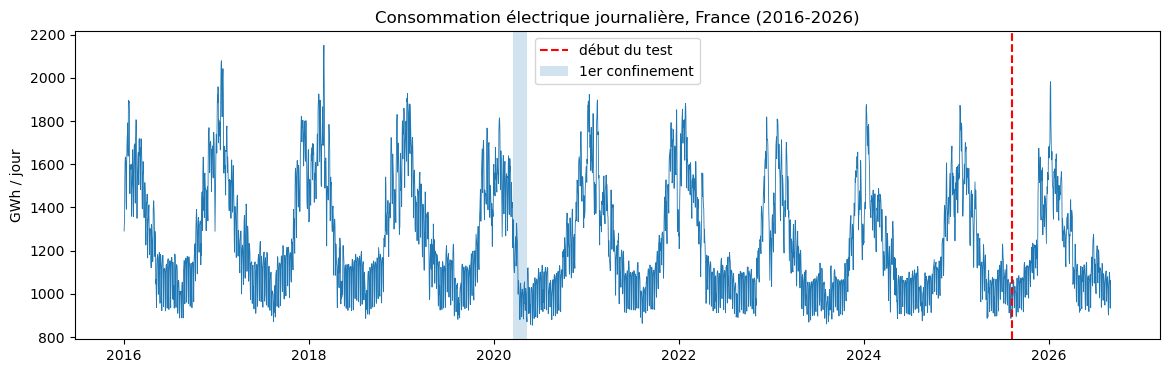

In [15]:
# Tracé de contrôle : repérer visuellement les ruptures et la frontière apprentissage/test avant toute modélisation.
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df.index, df["conso_gwh"], linewidth=0.6)
ax.axvline(pd.Timestamp("2025-08-07"), color="red", linestyle="--", label="début du test")
ax.axvspan(pd.Timestamp("2020-03-17"), pd.Timestamp("2020-05-11"), alpha=0.2, label="1er confinement")
ax.set_title("Consommation électrique journalière, France (2016-2026)")
ax.set_ylabel("GWh / jour")
ax.legend()
plt.show()